In [1]:
from src import utils
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, clear_output

root = Path.cwd().parent
data_dir = root / "data"

In [2]:
with open(data_dir / "trainingI.dat", "r") as training:
    X = []
    Y = []
    for line in training:
        x, y = map(float, line.split())
        X.append(x)
        Y.append(y)
    X = np.array(X)
    Y = np.array(Y) # b
    Y = Y.flatten()

In [3]:
m = 60
n = 8

A = np.zeros((m, n))
for i in range(m):
    for j in range(n):
        A[i, j] = utils.Legendre_poly(j, X[i])

theta = utils.naive_LSE(A, Y) 
display(Math(r"\theta=" + utils.np_to_latex(theta)))
display(Math(r"A=" + utils.np_to_latex(A)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Text(0.5, 0, 'x')

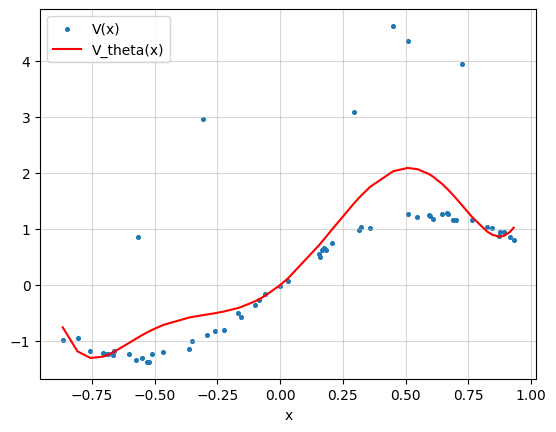

In [4]:
v_estimate_vec = np.array([utils.V_estimate(theta, x) for x in X])

plt.scatter(X, Y, label="V(x)", s=7)
plt.plot(X, v_estimate_vec, label="V_theta(x)", color="red")

plt.legend()
plt.grid(alpha=0.5)
plt.xlabel("x")
# plt.title("Least squares estimation versus ground truth")

Text(0.5, 0, 'x')

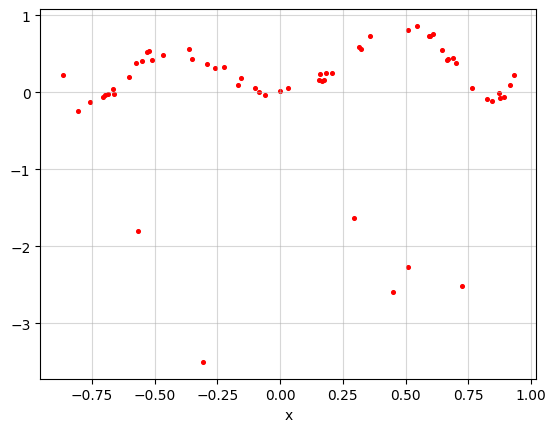

In [5]:
res = A @ theta - Y

plt.scatter(X, res, s=7, color="red")

plt.grid(alpha=0.5)
plt.xlabel("x")
# plt.title("Residuals of LSE")

In [6]:
with open(data_dir / "validationI.dat", "r") as validation:
    X_val = []
    Y_val = []
    for line in validation:
        x, y = map(float, line.split())
        X_val.append(x)
        Y_val.append(y)
    X_val = np.array(X_val)
    Y_val = np.array(Y_val)

m_val = len(X_val)

# V_theta(x_k)
V_val_estimate = np.array([utils.V_estimate(theta, x) for x in X_val])

val_mse = np.mean((V_val_estimate - Y_val) ** 2)
print(f"MSE={val_mse}")

MSE=0.34571727739664254


In [7]:
A_monomial = np.array([[x**i for i in range(n)] for x in X])
print(f"(monomial) kappa(A'A)={utils.get_condition_number(A_monomial.T @ A_monomial)}")

print(f"(Legendre) kappa(A'A)={utils.get_condition_number(A.T @ A)}")

(monomial) kappa(A'A)=139966.1886854216
(Legendre) kappa(A'A)=315.4474663137863


In [8]:
evalues = np.linalg.eigvals(A.T @ A)
sigma_max_sqr = evalues.max()

t = 1 / sigma_max_sqr
eps = 1e-3
rng = np.random.default_rng(seed=42)
theta_iter = rng.normal(size=n)

threshold = 1e-9
max_iter = 1e3
loss = utils.F(eps, theta_iter, A, Y)
last_loss = float("inf")
iter_cnt = 0

while np.abs(loss - last_loss) >= threshold and iter_cnt < max_iter:
    last_loss = loss.copy()
    theta_iter -= t * utils.F_grad(eps, theta_iter, A, Y)
    loss = utils.F(eps, theta_iter, A, Y)
    iter_cnt += 1
    clear_output()
    print(f"iteration:{iter_cnt} | loss = {loss}")

iteration:1000 | loss = 0.09385494571041268


In [12]:
for eps in 10 ** np.arange(-3, 1.5, 0.5):
    iter_cnt, final_theta, final_loss = utils.F_gd(A, Y, eps=eps)
    val_mse = utils.get_mse(final_theta, X_val, Y_val)
    print(f"eps = {eps:.3f} | {iter_cnt} iterations, loss = {final_loss:.6f}, MSE = {val_mse:.6f}")

eps = 0.001 | 28001 iterations, loss = 0.019450, MSE = 0.000604
eps = 0.003 | 9385 iterations, loss = 0.061319, MSE = 0.000532
eps = 0.010 | 2936 iterations, loss = 0.192128, MSE = 0.000538
eps = 0.032 | 1570 iterations, loss = 0.592552, MSE = 0.000279
eps = 0.100 | 1485 iterations, loss = 1.778772, MSE = 0.000278
eps = 0.316 | 886 iterations, loss = 5.251427, MSE = 0.003528
eps = 1.000 | 1793 iterations, loss = 13.950205, MSE = 0.056912
eps = 3.162 | 2076 iterations, loss = 22.106993, MSE = 0.323255
eps = 10.000 | 2086 iterations, loss = 22.170428, MSE = 0.345321
